# 📰 Web Scraping Berita detik.com + Text Preprocessing + TF-IDF

**Tugas Text Mining — Minggu 1**

Alur notebook:
1. **Scraping** halaman indeks berita `news.detik.com/indeks` dengan `requests` + `BeautifulSoup`
2. Mengambil **isi artikel** dari setiap tautan
3. **Preprocessing** bahasa Indonesia: case folding → cleaning → tokenizing → stopword removal → stemming (Sastrawi)
4. **Frekuensi term**, **inverted index**, dan **term-document matrix**
5. **TF-IDF** dengan scikit-learn, serta **perhitungan TF-IDF manual** sebagai pembuktian rumus

> ⚠️ Hasil scraping bergantung pada berita yang tayang saat notebook dijalankan, sehingga output akan berbeda jika dijalankan ulang. Hasil scraping saat pengerjaan tersimpan di folder `outputs/`.

## 1. Import Library

In [3]:
import re
import string
import time
from collections import Counter

import requests
import pandas as pd
from bs4 import BeautifulSoup

pd.set_option("display.max_colwidth", 120)
print("Library siap.")

Library siap.


## 2. Scraping Halaman Indeks Berita

In [ ]:
HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
        "(KHTML, like Gecko) Chrome/120.0 Safari/537.36"
    )
}

INDEX_URL = "https://news.detik.com/indeks"

def get_soup(url, timeout=15):
    resp = requests.get(url, headers=HEADERS, timeout=timeout)
    resp.raise_for_status()
    return BeautifulSoup(resp.text, "lxml")

soup_index = get_soup(INDEX_URL)
print("Judul halaman :", soup_index.title.get_text(strip=True))

Judul halaman : Indeks berita terbaru hari ini dari isu terkini di indonesia - 1


In [ ]:
kartu_berita = soup_index.find_all("article", class_="list-content__item")

if not kartu_berita:
    kartu_berita = soup_index.select("article, div.list-content__item")

print("Jumlah kartu berita ditemukan:", len(kartu_berita))

daftar_berita = []
for kartu in kartu_berita:
    tag_judul = kartu.find(["h2", "h3"])              
    tag_link = kartu.find("a", href=True)            
    if not tag_judul or not tag_link:
        continue
    daftar_berita.append({
        "judul": tag_judul.get_text(strip=True),
        "url": tag_link["href"].split("?")[0],
    })

seen, berita_unik = set(), []
for b in daftar_berita:
    if b["url"] not in seen:
        seen.add(b["url"])
        berita_unik.append(b)

df_index = pd.DataFrame(berita_unik)
print("Total berita unik:", len(df_index))
df_index.head(10)

Jumlah kartu berita ditemukan: 20
Total berita unik: 20


,judul,url
0,Mempertanyakan Ranking SGIE,https://news.detik.com/kolom/d-8660286/mempertanyakan-ranking-sgie
1,PJR Polda Riau Gerak Cepat Gagalkan Debt Collector Rampas Mobil di Tol,https://news.detik.com/melindungi-tuah-marwah/d-8660284/pjr-polda-riau-gerak-cepat-gagalkan-debt-collector-rampas-mo...
2,"Kafilah Padati Semarang, Wali Kota Sebut Pawai Ta'aruf Panggung Kebersamaan",https://news.detik.com/berita/d-8660278/kafilah-padati-semarang-wali-kota-sebut-pawai-taaruf-panggung-kebersamaan
3,"Hari ke-5 Pencarian 5 Jurnalis Hilang, Tim SAR Temukan Pelampung hingga Helm",https://news.detik.com/berita/d-8660277/hari-ke-5-pencarian-5-jurnalis-hilang-tim-sar-temukan-pelampung-hingga-helm
4,Momen Menteri Kebudayaan-Kapolri Hadiri Pembukaan Pameran Nasirun,https://news.detik.com/foto-news/d-8660259/momen-menteri-kebudayaan-kapolri-hadiri-pembukaan-pameran-nasirun
5,Video Anggota DPR Soroti Tak Ada Perhatian Khusus Karhutla di Sangihe Sulut,https://20.detik.com/detikupdate/20260912-260912036/video-anggota-dpr-soroti-tak-ada-perhatian-khusus-karhutla-di-sa...
6,"Momen Akrab Prabowo Bersama Putin, Xi Jinping hingga PM Modi Jelang KTT BRICS",https://news.detik.com/berita/d-8660253/momen-akrab-prabowo-bersama-putin-xi-jinping-hingga-pm-modi-jelang-ktt-brics
7,Video: Evakuasi WN Australia Tewas Terjatuh dari Tebing Pantai Kelingking Bali,https://20.detik.com/detikupdate/20260912-260912032/video-evakuasi-wn-australia-tewas-terjatuh-dari-tebing-pantai-ke...
8,"Sejarah Baru, Persib Vs Persija Bertemu di GBK Usai 7 Tahun Tanpa Insiden",https://news.detik.com/berita/d-8660248/sejarah-baru-persib-vs-persija-bertemu-di-gbk-usai-7-tahun-tanpa-insiden
9,"Prabowo, Putin, hingga Xi Jinping Tanam Pohon Banyan Bersama di Sela KTT BRICS",https://news.detik.com/berita/d-8660244/prabowo-putin-hingga-xi-jinping-tanam-pohon-banyan-bersama-di-sela-ktt-brics


## 3. Mengambil Isi Artikel

In [ ]:
JUMLAH_ARTIKEL = 10

def ambil_isi_artikel(url):
    try:
        soup = get_soup(url)
    except Exception as e:
        return None, f"gagal: {e}"

    body = (soup.select_one("div.detail__body-text")
            or soup.select_one("div.itp_bodycontent")
            or soup.select_one("div.detail_text")
            or soup.select_one("article"))
    if body is None:
        return None, "container isi tidak ditemukan"

    for buang in body.select("script, style, figure, figcaption, table, .para_caption, .lihatjg, .detail__long-desc"):
        buang.decompose()

    paragraf = [p.get_text(" ", strip=True) for p in body.find_all("p")]
    paragraf = [p for p in paragraf if len(p) > 40]          
    isi = " ".join(paragraf)
    return (isi, "ok") if isi else (None, "isi kosong")


hasil = []
for i, row in df_index.head(JUMLAH_ARTIKEL).iterrows():
    isi, status = ambil_isi_artikel(row["url"])
    print(f"[{i+1}/{JUMLAH_ARTIKEL}] {status:<12} | {row['judul'][:70]}")
    if isi:
        hasil.append({"judul": row["judul"], "url": row["url"], "isi": isi})
    time.sleep(1)

df = pd.DataFrame(hasil)
print("\nArtikel berhasil diambil:", len(df))
df[["judul", "isi"]].head()

[1/10] ok           | Mempertanyakan Ranking SGIE
[2/10] ok           | PJR Polda Riau Gerak Cepat Gagalkan Debt Collector Rampas Mobil di Tol
[3/10] ok           | Kafilah Padati Semarang, Wali Kota Sebut Pawai Ta'aruf Panggung Kebers
[4/10] ok           | Hari ke-5 Pencarian 5 Jurnalis Hilang, Tim SAR Temukan Pelampung hingg
[5/10] ok           | Momen Menteri Kebudayaan-Kapolri Hadiri Pembukaan Pameran Nasirun
[6/10] container isi tidak ditemukan | Video Anggota DPR Soroti Tak Ada Perhatian Khusus Karhutla di Sangihe 
[7/10] ok           | Momen Akrab Prabowo Bersama Putin, Xi Jinping hingga PM Modi Jelang KT
[8/10] container isi tidak ditemukan | Video: Evakuasi WN Australia Tewas Terjatuh dari Tebing Pantai Kelingk
[9/10] ok           | Sejarah Baru, Persib Vs Persija Bertemu di GBK Usai 7 Tahun Tanpa Insi
[10/10] ok           | Prabowo, Putin, hingga Xi Jinping Tanam Pohon Banyan Bersama di Sela K

Artikel berhasil diambil: 8


,judul,isi
0,Mempertanyakan Ranking SGIE,Masyarakat Ekonomi Syariah (MES) mempunyai gagasan besar untuk ikut mendorong Indonesia menjadi pemimpin ekonomi sya...
1,PJR Polda Riau Gerak Cepat Gagalkan Debt Collector Rampas Mobil di Tol,Satuan Patroli Jalan Raya (PJR) Ditlantas Polda Riau bergerak cepat menyelamatkan seorang pengendara mobil dari debt...
2,"Kafilah Padati Semarang, Wali Kota Sebut Pawai Ta'aruf Panggung Kebersamaan",Ribuan kafilah dari 38 provinsi memenuhi ruas jalan Kota Semarang dalam ajang Pawai Ta'aruf MTQ Nasional XXXI Tahun ...
3,"Hari ke-5 Pencarian 5 Jurnalis Hilang, Tim SAR Temukan Pelampung hingga Helm",Tim SAR gabungan masih belum menemukan titik terang keberadaan 5 jurnalis dan 3 kru kapal yang hilang di perairan Se...
4,Momen Menteri Kebudayaan-Kapolri Hadiri Pembukaan Pameran Nasirun,Jakarta - Menbud Fadli Zon dan Kapolri Jenderal Listyo Sigit Prabowo hadiri pembukaan Pameran Nasirun bertajuk 'Bers...


## 4. Text Preprocessing

Menyiapkan stemmer dan stopword bahasa Indonesia (Sastrawi + stopword tambahan khas portal berita).

In [ ]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stemmer = StemmerFactory().create_stemmer()
stopwords_id = set(StopWordRemoverFactory().get_stop_words())
stopwords_id |= {"detikcom", "detik", "baca", "juga", "foto", "simak", "video",
                 "jakarta", "adv", "ia", "nya", "kata", "ujar", "tuturnya"}

print("Jumlah stopword:", len(stopwords_id))
print("Contoh stemming:", stemmer.stem("pemerintah mendorong pemanfaatan teknologi"))

Jumlah stopword: 135
Contoh stemming: perintah dorong manfaat teknologi


In [ ]:
def case_folding(teks):
    return teks.lower()

def cleaning(teks):
    teks = re.sub(r"http\S+|www\.\S+", " ", teks)        
    teks = re.sub(r"\d+", " ", teks)                     
    teks = teks.translate(str.maketrans("", "", string.punctuation))  
    teks = re.sub(r"[^a-z\s]", " ", teks)                 
    teks = re.sub(r"\s+", " ", teks).strip()              
    return teks

def tokenizing(teks):
    return teks.split()

def hapus_stopword(tokens):
    return [t for t in tokens if t not in stopwords_id and len(t) > 2]

_cache_stem = {}
def stemming(tokens):
    hasil = []
    for t in tokens:
        if t not in _cache_stem:
            _cache_stem[t] = stemmer.stem(t)
        hasil.append(_cache_stem[t])
    return hasil


def preprocess(teks):
    teks = case_folding(teks)
    teks = cleaning(teks)
    tokens = tokenizing(teks)
    tokens = hapus_stopword(tokens)
    tokens = stemming(tokens)
    return tokens

### Contoh tahapan preprocessing pada satu artikel

In [ ]:
contoh = df.loc[0, "isi"]

print("0. TEKS ASLI\n", contoh[:300], "\n")
t1 = case_folding(contoh);     print("1. CASE FOLDING\n", t1[:300], "\n")
t2 = cleaning(t1);             print("2. CLEANING\n", t2[:300], "\n")
t3 = tokenizing(t2);           print("3. TOKENIZING", len(t3), "token\n", t3[:30], "\n")
t4 = hapus_stopword(t3);       print("4. STOPWORD REMOVAL", len(t4), "token\n", t4[:30], "\n")
t5 = stemming(t4);             print("5. STEMMING", len(t5), "token\n", t5[:30])

0. TEKS ASLI
 Masyarakat Ekonomi Syariah (MES) mempunyai gagasan besar untuk ikut mendorong Indonesia menjadi pemimpin ekonomi syariah dunia. Tantangannya nyata. Dalam State of the Global Islamic Economy Report (SGIE) 2025/2026 terbit Juni 2026, Indonesia berada di peringkat keempat Global Islamic Economy Indicat 

1. CASE FOLDING
 masyarakat ekonomi syariah (mes) mempunyai gagasan besar untuk ikut mendorong indonesia menjadi pemimpin ekonomi syariah dunia. tantangannya nyata. dalam state of the global islamic economy report (sgie) 2025/2026 terbit juni 2026, indonesia berada di peringkat keempat global islamic economy indicat 

2. CLEANING
 masyarakat ekonomi syariah mes mempunyai gagasan besar untuk ikut mendorong indonesia menjadi pemimpin ekonomi syariah dunia tantangannya nyata dalam state of the global islamic economy report sgie terbit juni indonesia berada di peringkat keempat global islamic economy indicator giei turun satu tin 

3. TOKENIZING 874 token
 ['masyarakat', 'ekonom

### Preprocessing seluruh artikel

In [ ]:
df["tokens"] = df["isi"].apply(preprocess)
df["teks_bersih"] = df["tokens"].apply(" ".join)
df["jumlah_token"] = df["tokens"].apply(len)

df[["judul", "jumlah_token", "teks_bersih"]]

,judul,jumlah_token,teks_bersih
0,Mempertanyakan Ranking SGIE,666,masyarakat ekonomi syariah mes punya gagas besar ikut dorong indonesia jadi pimpin ekonomi syariah dunia tantang nya...
1,PJR Polda Riau Gerak Cepat Gagalkan Debt Collector Rampas Mobil di Tol,333,satu patroli jalan raya pjr ditlantas polda riau gerak cepat selamat orang kendara mobil debt collector hendak tarik...
2,"Kafilah Padati Semarang, Wali Kota Sebut Pawai Ta'aruf Panggung Kebersamaan",279,ribu kafilah provinsi penuh ruas jalan kota semarang ajang pawai taaruf mtq nasional xxxi tahun sabtu serta tempuh r...
3,"Hari ke-5 Pencarian 5 Jurnalis Hilang, Tim SAR Temukan Pelampung hingga Helm",180,tim sar gabung temu titik terang ada jurnalis kru kapal hilang air selat sunda liput aktivitas gunung anak krakatau ...
4,Momen Menteri Kebudayaan-Kapolri Hadiri Pembukaan Pameran Nasirun,19,menbud fadli zon kapolri jenderal listyo sigit prabowo hadir buka pamer nasirun tajuk simpuh kaki guru galeri nasion...
5,"Momen Akrab Prabowo Bersama Putin, Xi Jinping hingga PM Modi Jelang KTT BRICS",178,momen akrab pimpin negara anggota brics lihat jelang buka ktt momen sebut lihat presiden prabowo subianto bincang sa...
6,"Sejarah Baru, Persib Vs Persija Bertemu di GBK Usai 7 Tahun Tanpa Insiden",248,persija persib bandung temu stadion gelora bung karno gbk tujuh tahun tanding macan mayor lawan maung bandung sekali...
7,"Prabowo, Putin, hingga Xi Jinping Tanam Pohon Banyan Bersama di Sela KTT BRICS",191,presiden prabowo subianto ikut giat tanam pohon sama joint tree plantation sama pimpin negara anggota rangkai konfer...


## 5. Frekuensi Term

In [ ]:
semua_token = [t for tokens in df["tokens"] for t in tokens]
freq = Counter(semua_token)

df_freq = pd.DataFrame(freq.most_common(20), columns=["term", "frekuensi"])
print("Total token:", len(semua_token), "| Term unik:", len(freq))
df_freq

Total token: 2094 | Term unik: 794


,term,frekuensi
0,jadi,29
1,syariah,28
2,indonesia,25
3,sama,22
4,sebut,20
5,temu,20
6,ekonomi,16
7,hasil,16
8,masyarakat,14
9,halal,14


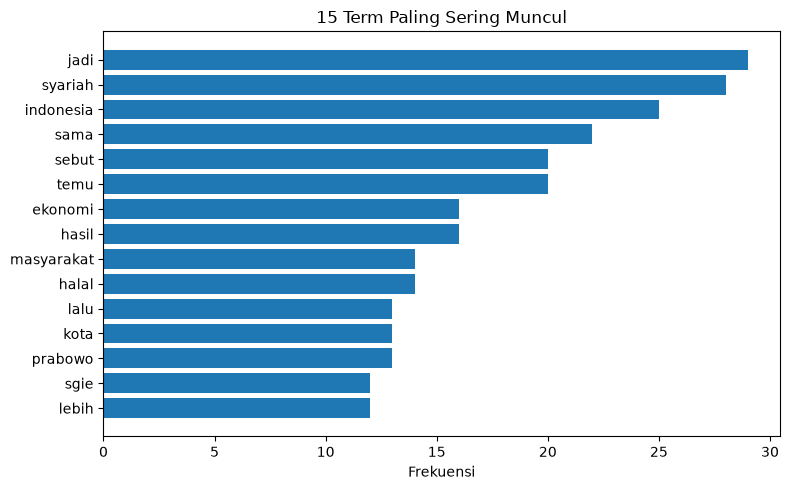

In [13]:
import matplotlib.pyplot as plt

top = df_freq.head(15).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["term"], top["frekuensi"])
plt.title("15 Term Paling Sering Muncul")
plt.xlabel("Frekuensi")
plt.tight_layout()
plt.show()

## 6. Inverted Index

In [ ]:
inverted_index = {}
for doc_id, tokens in enumerate(df["tokens"]):
    for term, jml in Counter(tokens).items():
        inverted_index.setdefault(term, {})[doc_id] = jml

print("isi inverted index:")
for term in list(df_freq["term"])[:8]:
    print(f"  {term:<15} -> {inverted_index.get(term, {})}")

Contoh isi inverted index:
  jadi            -> {0: 12, 1: 3, 2: 8, 5: 2, 6: 2, 7: 2}
  syariah         -> {0: 28}
  indonesia       -> {0: 19, 4: 1, 5: 3, 6: 2}
  sama            -> {0: 1, 1: 1, 2: 4, 3: 1, 5: 3, 6: 3, 7: 9}
  sebut           -> {0: 4, 1: 4, 2: 3, 3: 1, 5: 5, 6: 1, 7: 2}
  temu            -> {0: 1, 2: 3, 3: 8, 5: 3, 6: 5}
  ekonomi         -> {0: 16}
  hasil           -> {0: 13, 2: 1, 3: 1, 6: 1}


## 7. Term-Document Matrix & TF-IDF

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cv = CountVectorizer()
X_count = cv.fit_transform(df["teks_bersih"])
df_tdm = pd.DataFrame(X_count.toarray(), columns=cv.get_feature_names_out(),
                      index=[f"D{i+1}" for i in range(len(df))])
print("Ukuran matriks term-document:", df_tdm.shape)
df_tdm.iloc[:, :15]

Ukuran matriks term-document: (8, 794)


,abadi,abdel,acara,account,ada,agam,agenda,agus,agustina,aipda,air,ajak,ajang,akademik,akar
D1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0
D2,0,0,0,0,3,0,0,0,0,1,0,1,0,0,0
D3,0,0,1,0,1,3,0,1,4,0,0,0,1,0,0
D4,0,0,0,0,1,0,0,0,0,0,2,0,0,0,0
D5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
D6,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0
D7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
D8,2,1,0,0,0,0,1,0,0,0,0,0,0,0,1


In [ ]:
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(df["teks_bersih"])
df_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=tfidf.get_feature_names_out(),
                        index=[f"D{i+1}" for i in range(len(df))])

print("Ukuran matriks TF-IDF:", df_tfidf.shape)
print("\nTerm dengan bobot TF-IDF tertinggi per dokumen:")
for idx in df_tfidf.index:
    top_terms = df_tfidf.loc[idx].sort_values(ascending=False).head(5)
    print(f"\n{idx} — {df.loc[int(idx[1:])-1, 'judul'][:60]}")
    for term, bobot in top_terms.items():
        print(f"   {term:<18} {bobot:.4f}")

Ukuran matriks TF-IDF: (8, 794)

Term dengan bobot TF-IDF tertinggi per dokumen:

D1 — Mempertanyakan Ranking SGIE
   syariah            0.4891
   ekonomi            0.2795
   halal              0.2445
   indonesia          0.2104
   sgie               0.2096

D2 — PJR Polda Riau Gerak Cepat Gagalkan Debt Collector Rampas Mo
   kendara            0.3008
   pjr                0.2632
   tol                0.2632
   polisi             0.2256
   aman               0.1576

D3 — Kafilah Padati Semarang, Wali Kota Sebut Pawai Ta'aruf Pangg
   kota               0.4585
   semarang           0.3880
   pawai              0.2821
   mtq                0.2116
   kafilah            0.2116

D4 — Hari ke-5 Pencarian 5 Jurnalis Hilang, Tim SAR Temukan Pelam
   cari               0.4192
   sar                0.4192
   temu               0.2091
   kantor             0.1952
   sektor             0.1952

D5 — Momen Menteri Kebudayaan-Kapolri Hadiri Pembukaan Pameran Na
   kapolri            0.2510
   zon  

## 8. Perhitungan TF-IDF Manual

Pembuktian rumus pada 3 dokumen sederhana:

$$TF(t,d) = \frac{f_{t,d}}{\sum_k f_{k,d}} \qquad IDF(t) = \log_{10}\frac{N}{DF(t)} \qquad TF\text{-}IDF = TF \times IDF$$

In [18]:
import math
from collections import Counter

dokumen = {
    "D1": "data mining data",
    "D2": "data science",
    "D3": "machine learning",
}

tokens_doc = {d: t.split() for d, t in dokumen.items()}
N = len(dokumen)

def hitung_tf(term, doc):
    tokens = tokens_doc[doc]
    return tokens.count(term) / len(tokens)

def hitung_df(term):
    return sum(1 for tokens in tokens_doc.values() if term in tokens)

def hitung_idf(term):
    df_t = hitung_df(term)
    return math.log10(N / df_t) if df_t else 0.0

def hitung_tfidf(term, doc):
    return hitung_tf(term, doc) * hitung_idf(term)


print(f"1. TF('data', D1)          = {hitung_tf('data', 'D1'):.4f}")
print(f"2. DF('data')              = {hitung_df('data')}")
print(f"3. IDF('data')             = {hitung_idf('data'):.4f}")
print(f"4. TF-IDF('data', D1)      = {hitung_tfidf('data', 'D1'):.4f}")
print(f"5. TF-IDF('science', D2)   = {hitung_tfidf('science', 'D2'):.4f}")

1. TF('data', D1)          = 0.6667
2. DF('data')              = 2
3. IDF('data')             = 0.1761
4. TF-IDF('data', D1)      = 0.1174
5. TF-IDF('science', D2)   = 0.2386


In [ ]:
kosakata = sorted({t for tokens in tokens_doc.values() for t in tokens})

baris = []
for term in kosakata:
    baris.append({
        "term": term,
        "TF_D1": round(hitung_tf(term, "D1"), 4),
        "TF_D2": round(hitung_tf(term, "D2"), 4),
        "TF_D3": round(hitung_tf(term, "D3"), 4),
        "DF": hitung_df(term),
        "IDF": round(hitung_idf(term), 4),
    })

tabel = pd.DataFrame(baris).set_index("term")
tabel

,TF_D1,TF_D2,TF_D3,DF,IDF
term,,,,,
data,0.6667,0.5,0.0,2,0.1761
learning,0.0000,0.0,0.5,1,0.4771
machine,0.0000,0.0,0.5,1,0.4771
mining,0.3333,0.0,0.0,1,0.4771
science,0.0000,0.5,0.0,1,0.4771


In [ ]:
matriks = pd.DataFrame(
    [[round(hitung_tfidf(term, doc), 4) for term in kosakata] for doc in dokumen],
    index=list(dokumen.keys()), columns=kosakata
)
print("Matriks TF-IDF (perhitungan manual):")
matriks

Matriks TF-IDF (perhitungan manual):


,data,learning,machine,mining,science
D1,0.1174,0.0000,0.0000,0.159,0.0000
D2,0.0880,0.0000,0.0000,0.000,0.2386
D3,0.0000,0.2386,0.2386,0.000,0.0000


### Perbandingan dengan `TfidfVectorizer` scikit-learn

Nilainya berbeda dari perhitungan manual karena scikit-learn memakai *smooth IDF* ($\ln\frac{1+N}{1+DF}+1$) dan normalisasi L2 per dokumen.

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer()
M = vec.fit_transform(dokumen.values())
pd.DataFrame(M.toarray().round(4), index=list(dokumen.keys()),
             columns=vec.get_feature_names_out())

,data,learning,machine,mining,science
D1,0.8356,0.0000,0.0000,0.5494,0.000
D2,0.6053,0.0000,0.0000,0.0000,0.796
D3,0.0000,0.7071,0.7071,0.0000,0.000
